# 02 · EDA

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt


In [4]:
DATA = Path("../data/processed")
LABELS = ["toxic", "severe_toxic", "obscene", "threat", "insult", "identity_hate"]

tox = pd.read_csv(DATA / "toxicity" / "train.csv")
spam = pd.read_csv(DATA / "spam" / "train.csv")
print("Toxicity train:", tox.shape, "| Spam train:", spam.shape)


Toxicity train: (111432, 10) | Spam train: (3600, 4)


               positives  percent
toxic              10675     9.58
obscene             5839     5.24
insult              5448     4.89
severe_toxic        1101     0.99
identity_hate        977     0.88
threat               332     0.30


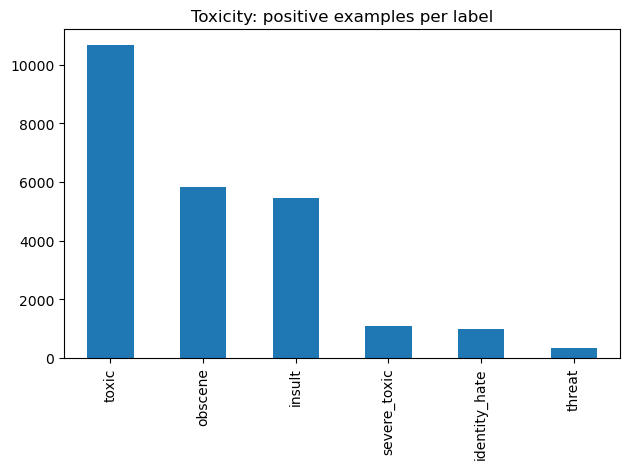

In [5]:
counts = tox[LABELS].sum().sort_values(ascending=False)
print(pd.DataFrame({"positives": counts, "percent": (counts / len(tox) * 100).round(2)}))

counts.plot(kind="bar", title="Toxicity: positive examples per label")
plt.tight_layout()
plt.show()

label
ham     3162
spam     438
Name: count, dtype: int64


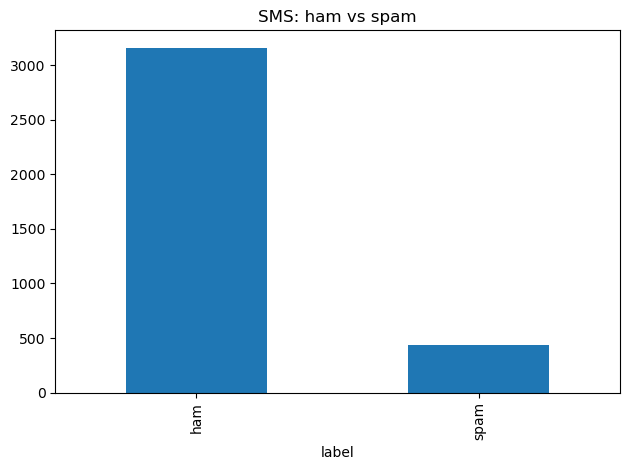

In [6]:
print(spam["label"].value_counts())
spam["label"].value_counts().plot(kind="bar", title="SMS: ham vs spam")
plt.tight_layout()
plt.show()

count    111432.0
mean        386.3
std         578.8
min           1.0
25%          92.0
50%         201.0
75%         429.0
max        5000.0
Name: length, dtype: float64
count    3600.0
mean       78.5
std        57.9
min         2.0
25%        36.0
50%        60.0
75%       115.2
max       910.0
Name: length, dtype: float64


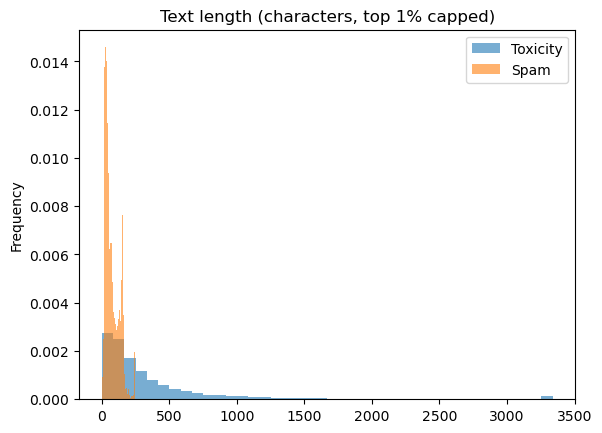

In [7]:
tox["length"] = tox["clean_text"].fillna("").str.len()
spam["length"] = spam["clean_text"].fillna("").str.len()

print(tox["length"].describe().round(1))
print(spam["length"].describe().round(1))

for d, name in [(tox, "Toxicity"), (spam, "Spam")]:
    d["length"].clip(upper=d["length"].quantile(0.99)).plot(kind="hist", bins=40, alpha=0.6, density=True, label=name)
plt.legend()
plt.title("Text length (characters, top 1% capped)")
plt.show()

In [8]:
print("TOXIC:")
for t in tox[tox["toxic"] == 1]["clean_text"].sample(3, random_state=1): print("-", t[:150])
print("\nSPAM:")
for t in spam[spam["spam"] == 1]["clean_text"].sample(3, random_state=1): print("-", t[:150])

TOXIC:
- u suckkk
- " gee, 5 minutes of reverting redirects cost you precious time. i am sooo sorry bout that. i have been back to the page and, aside from revisiting bur
- i hope that one day one of your pupils drinks sulphuric acid that you have carelessly left out in a bottle of water. it will be a shame, but you will 

SPAM:
- win a £1000 cash prize or a prize worth £5000
- todays voda numbers ending with 7634 are selected to receive a £350 reward. if you have a match please call longnumber quoting claim code 7684 standar
- send a logo 2 ur lover - 2 names joined by a heart. txt love name1 name2 mobno eg love adam eve longnumber to longnumber yahoo! pobox longnumber w45wq


In [9]:
for name, d in [("Toxicity", tox), ("Spam", spam)]:
    print(name, "| missing:", d["clean_text"].isnull().sum(), "| duplicates:", d["clean_text"].duplicated().sum())

Toxicity | missing: 0 | duplicates: 0
Spam | missing: 0 | duplicates: 0


## Summary
- Toxicity labels are imbalanced: toxic is about 9.6% and threat about 0.3%.
- Spam is about 12% of the SMS data.
- Jigsaw comments are much longer than SMS messages.
- Because of the imbalance, we report precision, recall and F1, not just accuracy.